# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [2]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [3]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [4]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

# Une date qui commence par l'année (2024-03-05, 2024/03/05, 20240305) ne doit JAMAIS
# être lue avec dayfirst=True : pandas échangerait alors le jour et le mois.
YEAR_FIRST_PATTERN = r'^(?:\d{4}[-/.]\d{1,2}[-/.]\d{1,2}|\d{8})'


def _parse_mixed(series: pd.Series) -> pd.Series:
    """Parse des dates de formats variés : jour d'abord, sauf si l'année est en tête."""
    if pd.api.types.is_datetime64_any_dtype(series):
        return series
    text = series.reset_index(drop=True).astype('string').str.strip()
    year_first = text.str.match(YEAR_FIRST_PATTERN).fillna(False).astype(bool)

    parts = []
    for mask, dayfirst in [(year_first, False), (~year_first, True)]:
        if mask.any():
            parts.append(pd.to_datetime(text[mask], format='mixed',
                                        dayfirst=dayfirst, errors='coerce'))
    if not parts:
        return pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')
    parsed = pd.concat(parts).reindex(range(len(text)))
    parsed.index = series.index
    return parsed


def parse_dates(series, min_success_rate=0.95):
    """Convertit une série de dates hétérogènes et renvoie (dates, rapport).

    Le rapport contient : n_total, n_already_missing, n_failed, success_rate,
    min_date, max_date. Lève une ValueError si le taux de réussite (calculé sur
    les valeurs réellement renseignées) est inférieur à min_success_rate.
    """
    parsed = _parse_mixed(series)

    n_total = len(series)
    n_already_missing = int(series.isna().sum())
    n_failed = max(int(parsed.isna().sum()) - n_already_missing, 0)
    n_filled = n_total - n_already_missing
    success_rate = 1.0 if n_filled == 0 else 1 - n_failed / n_filled

    report = {
        'n_total': n_total,
        'n_already_missing': n_already_missing,
        'n_failed': n_failed,
        'success_rate': round(success_rate, 4),
        'min_date': parsed.min(),
        'max_date': parsed.max(),
    }
    if success_rate < min_success_rate:
        raise ValueError(
            f'Taux de réussite {success_rate:.1%} inférieur au seuil {min_success_rate:.0%} '
            f'({n_failed} échecs sur {n_filled} dates renseignées)')
    return parsed, report


order_dates, report = parse_dates(raw_sales['date_commande'])
print(report)

# Le garde-fou fonctionne : un taux de réussite trop bas lève une erreur au lieu de passer sous silence
try:
    parse_dates(pd.Series(['abc', 'def', '05/03/2024']))
except ValueError as error:
    print('ValueError attendue :', error)

{'n_total': 17609, 'n_already_missing': 350, 'n_failed': 0, 'success_rate': 1.0, 'min_date': Timestamp('2023-01-01 00:00:00'), 'max_date': Timestamp('2024-12-30 17:10:00')}
ValueError attendue : Taux de réussite 33.3% inférieur au seuil 95% (2 échecs sur 3 dates renseignées)


In [6]:
# Contrôle : que donne le parsing « naïf » (dayfirst=True partout) face à notre fonction ?
# Les dates écrites année-mois-jour (2024-03-05) sont lues 3 mai au lieu de 5 mars avec dayfirst=True.
naive = pd.to_datetime(raw_sales['date_commande'], format='mixed', dayfirst=True, errors='coerce')
both = naive.notna() & order_dates.notna()
n_swapped = int((naive[both] != order_dates[both]).sum())
print(f'Dates dont le jour et le mois sont inversés avec le parsing naïf : {n_swapped} sur {both.sum()}')

# Le jeu issu des séances précédentes est-il touché ? (comparaison par id_commande)
if dataset_exists('ventes_transformees'):
    previous = load_dataset('ventes_transformees')[['id_commande', 'date_commande']]
    reference = (pd.DataFrame({'id_commande': raw_sales['id_commande'], 'date_juste': order_dates})
                 .drop_duplicates('id_commande'))
    compared = previous.merge(reference, on='id_commande', how='inner')
    n_wrong = int((pd.to_datetime(compared['date_commande']).dt.normalize()
                   != compared['date_juste'].dt.normalize()).sum())
    print(f'Lignes de ventes_transformees dont la date diffère de la date correcte : {n_wrong} sur {len(compared)}')

Dates dont le jour et le mois sont inversés avec le parsing naïf : 0 sur 17259
Lignes de ventes_transformees dont la date diffère de la date correcte : 0 sur 17022


---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [7]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-11-02 00:00:00,2024,11,Saturday,44,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [8]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [9]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).

# Colonnes de clients.csv : à vérifier avec clients.columns si l'erreur KeyError apparaît.
CLIENT_ID_COL = 'id_client'
CLIENT_SIGNUP_COL = 'date_inscription'

order_dt = sales['date_commande'].dt

# 1. Période de la journée : matin (< 12 h), après-midi (12 h - 17 h), soir (>= 18 h)
sales['periode_journee'] = np.select([sales['heure'] < 12, sales['heure'] < 18],
                                     ['matin', 'apres-midi'], default='soir')
print('Heures distinctes dans les données :', sales['heure'].nunique(),
      '(si 1 seule, les dates n\'ont pas d\'heure et periode_journee n\'a aucun sens)')

# 2. Fin de mois : les trois derniers jours (jour > nombre de jours du mois - 3)
sales['est_fin_de_mois'] = order_dt.day > order_dt.days_in_month - 3

# 3. Jours écoulés depuis la première commande
first_day = sales['date_commande'].min().normalize()
sales['jours_depuis_debut'] = (sales['date_commande'].dt.normalize() - first_day).dt.days

# 4. Ancienneté du client : jointure avec clients.csv (une ligne par client attendue)
clients = pd.read_csv(RAW_DIR / 'clients.csv')
signup_dates, signup_report = parse_dates(clients[CLIENT_SIGNUP_COL])
print('Dates d\'inscription :', signup_report)
signups = pd.DataFrame({CLIENT_ID_COL: clients[CLIENT_ID_COL], 'date_inscription': signup_dates})

n_rows = len(sales)
sales = sales.merge(signups, on=CLIENT_ID_COL, how='left', validate='many_to_one')
assert len(sales) == n_rows, 'la jointure a changé le nombre de lignes'

sales['anciennete_client_jours'] = (sales['date_commande'].dt.normalize()
                                    - sales['date_inscription']).dt.days
sales = sales.drop(columns='date_inscription')

# Contrôles de cohérence
print('Clients sans date d\'inscription :', int(sales['anciennete_client_jours'].isna().sum()))
print('Commandes AVANT l\'inscription (ancienneté négative) :',
      int((sales['anciennete_client_jours'] < 0).sum()))
print(sales['periode_journee'].value_counts())
sales[['date_commande', 'periode_journee', 'est_fin_de_mois',
       'jours_depuis_debut', 'anciennete_client_jours']].head()

Heures distinctes dans les données : 14 (si 1 seule, les dates n'ont pas d'heure et periode_journee n'a aucun sens)
Dates d'inscription : {'n_total': 3060, 'n_already_missing': 0, 'n_failed': 0, 'success_rate': 1.0, 'min_date': Timestamp('2019-01-01 00:00:00'), 'max_date': Timestamp('2024-06-22 00:00:00')}
Clients sans date d'inscription : 0
Commandes AVANT l'inscription (ancienneté négative) : 1743
periode_journee
matin         14622
apres-midi     1571
soir            829
Name: count, dtype: int64


,date_commande,periode_journee,est_fin_de_mois,jours_depuis_debut,anciennete_client_jours
0,2024-01-18 19:53:00,soir,False,382,1005
1,2024-01-08 00:00:00,matin,False,372,-42
2,2023-04-15 00:00:00,matin,False,104,1511
3,2024-11-06 00:00:00,matin,False,675,1985
4,2024-11-02 00:00:00,matin,False,671,1400


In [10]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.

# 1. Montant moyen par commande : week-end contre semaine
by_weekend = (sales.groupby('est_weekend')['montant']
              .agg(['count', 'mean', 'median', 'std']).round(2))
print(by_weekend)

# L'écart est-il plus grand que le bruit ? (statistique de Welch, sans bibliothèque)
weekend_amounts = sales.loc[sales['est_weekend'], 'montant']
weekday_amounts = sales.loc[~sales['est_weekend'], 'montant']
difference = weekend_amounts.mean() - weekday_amounts.mean()
std_error = np.sqrt(weekend_amounts.var() / len(weekend_amounts)
                    + weekday_amounts.var() / len(weekday_amounts))
t_stat = difference / std_error
print(f'\nÉcart week-end - semaine : {difference:+.2f} EUR '
      f'({difference / weekday_amounts.mean():+.1%}), t = {t_stat:.2f}')
print('Lecture :', 'écart discernable du bruit (|t| >= 2)' if abs(t_stat) >= 2
      else 'écart noyé dans la variabilité (|t| < 2)')

# 2. Montant moyen selon le jour de la semaine (ordre lundi -> dimanche)
by_day = (sales.groupby(['jour_semaine', 'nom_jour'])['montant']
          .agg(['count', 'mean', 'median']).round(2))
print('\n', by_day)

# 3. Chiffre d'affaires par jour calendaire : deux jours de week-end contre cinq jours de semaine
daily_revenue = sales.groupby(sales['date_commande'].dt.normalize())['montant'].sum()
revenue_by_type = daily_revenue.groupby(daily_revenue.index.dayofweek >= 5).mean().round(0)
revenue_by_type.index = ['semaine', 'week-end']
print('\nChiffre d\'affaires moyen par jour :')
print(revenue_by_type)

# Commentaire : le montant moyen PAR COMMANDE et le chiffre d'affaires PAR JOUR répondent à deux
# questions différentes. Une commande de week-end peut ne pas être plus grosse alors que le
# week-end rapporte plus (ou moins) chaque jour parce qu'il y a plus (ou moins) de commandes.
# Conclure à une différence réelle suppose que l'écart dépasse le bruit (|t| >= 2) ET qu'il se
# retrouve dans la médiane, pas seulement dans la moyenne tirée par quelques gros montants.

             count     mean   median       std
est_weekend                                   
False        12204  2305.05  1020.32  23265.76
True          4818  3718.53  1050.99  40739.33

Écart week-end - semaine : +1413.48 EUR (+61.3%), t = 2.27
Lecture : écart discernable du bruit (|t| >= 2)

                         count     mean   median
jour_semaine nom_jour                          
0            Monday      2490  2102.65  1030.58
1            Tuesday     2451  2148.87   999.53
2            Wednesday   2359  2632.78   999.00
3            Thursday    2429  2417.86  1019.36
4            Friday      2475  2240.27  1054.97
5            Saturday    2383  3431.08  1051.48
6            Sunday      2435  3999.83  1050.33

Chiffre d'affaires moyen par jour :
semaine     53994.0
week-end    85722.0
Name: montant, dtype: float64


In [11]:
# Export du jeu de ventes enrichi de ses variables temporelles (livrable de la séance).
save_dataset(sales, 'ventes_temporelles')

écrit : ventes_temporelles.parquet (17022, 37)


WindowsPath('c:/Users/Utilisateur/Desktop/cours coda/Preparation et manipulation des données/TP V1_DOGO/data/processed/ventes_temporelles.parquet')

---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [12]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [13]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [14]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.

def detect_outages(frame, min_hours=24, freq='h'):
    """Plages sans aucune mesure de plus de min_hours heures.

    `frame` est indexé par horodatage et ne contient que des colonnes de mesures.
    Une heure est « sans mesure » si aucune colonne n'a de valeur valide.
    """
    valid_per_hour = frame.resample(freq).count().sum(axis=1)     # mesures valides par heure
    missing = valid_per_hour.eq(0)                                # heure sans aucune mesure
    run_id = missing.ne(missing.shift()).cumsum()                 # numéro de chaque suite

    gap_times = missing[missing].index.to_series()
    gaps = gap_times.groupby(run_id[missing]).agg(debut='first', fin='last', n_heures='size')
    return gaps[gaps['n_heures'] > min_hours].reset_index(drop=True)


measure_columns = sensors.select_dtypes('number').columns.tolist()

for sensor_id, group in sensors.groupby('id_capteur'):
    frame = group.set_index('horodatage').sort_index()[measure_columns]
    outages = detect_outages(frame)
    print(f'{sensor_id} : {len(outages)} panne(s) de plus de 24 h')
    if len(outages):
        print(outages.to_string(index=False))

CAP-A : 0 panne(s) de plus de 24 h
CAP-B : 1 panne(s) de plus de 24 h
     debut                 fin  n_heures
2024-06-03 2024-06-13 23:00:00       264
CAP-C : 0 panne(s) de plus de 24 h


In [15]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.

def detect_stuck_periods(series, min_readings=24):
    """Périodes où la valeur reste strictement constante sur plus de min_readings relevés.

    Les valeurs manquantes interrompent une suite : un trou n'est pas un blocage.
    """
    run_id = series.ne(series.shift()).cumsum()                   # nouvelle suite à chaque changement
    run_size = series.groupby(run_id).transform('size')           # longueur de la suite de chaque ligne
    stuck = (run_size > min_readings) & series.notna()

    rows = pd.DataFrame({'t': series.index, 'valeur': series.values,
                         'suite': run_id.values})[stuck.values]
    return (rows.groupby('suite')
                .agg(debut=('t', 'first'), fin=('t', 'last'),
                     valeur=('valeur', 'first'), n_releves=('valeur', 'size'))
                .reset_index(drop=True))


for sensor_id, group in sensors.groupby('id_capteur'):
    ordered = group.set_index('horodatage').sort_index()
    for column in measure_columns:
        stuck_periods = detect_stuck_periods(ordered[column])
        if len(stuck_periods):
            print(f'{sensor_id} / {column} : {len(stuck_periods)} période(s) bloquée(s)')
            print(stuck_periods.to_string(index=False), '\n')

CAP-C / temperature_c : 2 période(s) bloquée(s)
              debut                 fin  valeur  n_releves
2024-09-10 01:00:00 2024-09-12 05:00:00    17.4         53
2024-09-12 07:00:00 2024-09-14 09:00:00    17.4         51 



               toutes_commandes   livrees
date_commande                            
2024-12-22             244692.0  178646.0
2024-12-29            1238804.0  181946.0
2025-01-05              42063.0   26705.0 

               toutes_commandes    livrees
date_commande                             
2023-01-01            2093636.0  1014205.0
2023-02-01            1488783.0  1215879.0
2023-03-01            2523004.0  1594985.0
2023-04-01            2475651.0  2089590.0
2023-05-01            2178448.0  1910729.0
2023-06-01            1952696.0  1639336.0
2023-07-01            3354929.0  3066701.0
2023-08-01             720866.0   525789.0
2023-09-01            2090287.0   600316.0
2023-10-01             879730.0   592626.0
2023-11-01            2535716.0  2135739.0
2023-12-01            1179024.0   790688.0
2024-01-01            2486642.0  1252698.0
2024-02-01            1544544.0   632163.0
2024-03-01            1730778.0  1406236.0
2024-04-01            2013186.0   894039.0
2024-05-01    

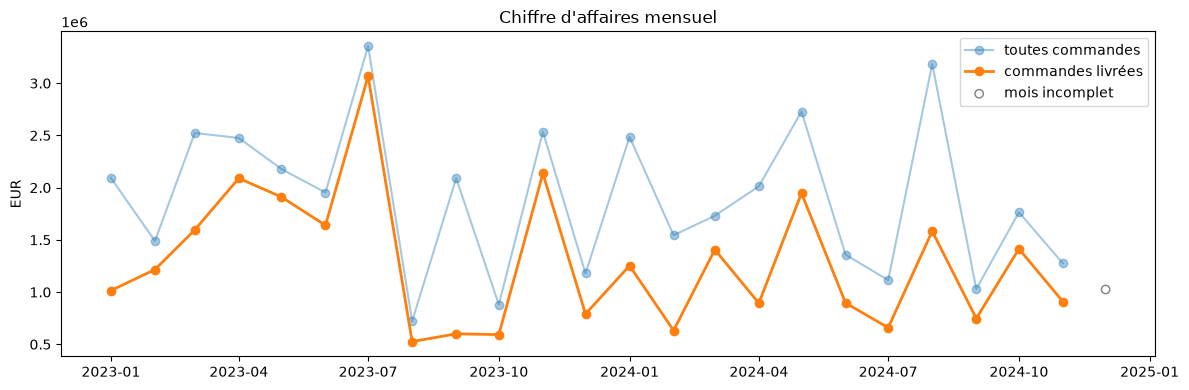


Mois calendaires les plus forts : {5: 1928885.0, 7: 1862849.0, 11: 1522038.0}
Mois calendaires les plus faibles : {9: 673691.0, 12: 790688.0, 2: 924021.0}


In [16]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.

import matplotlib.pyplot as plt

DELIVERED_STATUS = 'livre'

revenue_all = sales.set_index('date_commande')['montant']
revenue_delivered = sales.loc[sales['statut'] == DELIVERED_STATUS].set_index('date_commande')['montant']

# Agrégation par semaine (semaines se terminant le dimanche) puis par mois (étiquette = 1er du mois)
weekly = pd.DataFrame({'toutes_commandes': revenue_all.resample('W').sum(),
                       'livrees': revenue_delivered.resample('W').sum()})
monthly = pd.DataFrame({'toutes_commandes': revenue_all.resample('MS').sum(),
                        'livrees': revenue_delivered.resample('MS').sum()})
print(weekly.tail(3).round(0), '\n')
print(monthly.round(0))

# Le premier et le dernier mois sont souvent incomplets : on les repère pour ne pas les interpréter
first_day = sales['date_commande'].min().normalize()
last_day = sales['date_commande'].max().normalize()
partial = pd.Series(False, index=monthly.index)
if first_day.day != 1:
    partial.iloc[0] = True
if last_day != last_day + pd.offsets.MonthEnd(0):
    partial.iloc[-1] = True
print('\nMois incomplets (à ne pas interpréter) :', [d.strftime('%Y-%m') for d in partial[partial].index])

fig, ax = plt.subplots(figsize=(12, 4))
complete = monthly[~partial]
ax.plot(complete.index, complete['toutes_commandes'], marker='o', alpha=0.4, label='toutes commandes')
ax.plot(complete.index, complete['livrees'], marker='o', linewidth=2, label='commandes livrées')
if partial.any():
    ax.scatter(monthly[partial].index, monthly[partial]['livrees'], facecolors='none',
               edgecolors='grey', label='mois incomplet')
ax.set_title('Chiffre d\'affaires mensuel')
ax.set_ylabel('EUR')
ax.legend()
plt.tight_layout()
plt.show()

# Profil saisonnier : moyenne par mois calendaire (seulement si l'on couvre plus d'un an)
seasonal = complete['livrees'].groupby(complete.index.month).mean().round(0)
print('\nMois calendaires les plus forts :', seasonal.nlargest(3).to_dict())
print('Mois calendaires les plus faibles :', seasonal.nsmallest(3).to_dict())

# Commentaire à rédiger avec VOS chiffres, en trois points :
#  1. la forme : pic(s) et creux visibles, et s'ils reviennent à la même période d'une année à l'autre
#     (c'est cela, la saisonnalité, et non un simple pic isolé) ;
#  2. l'ordre de grandeur : écart entre le mois le plus fort et le plus faible, en % de la moyenne ;
#  3. la prudence : mois incomplets exclus, et nombre d'années couvertes (avec 18 mois, un mois donné
#     n'est observé qu'une ou deux fois : on parle d'indice, pas de preuve).

---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.